<a href="https://colab.research.google.com/github/eltalachas69/ProyectoCardio/blob/main/Conjunto_Cardio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enfermedades Cardiovascular
#enfermedad cardiovascular
Etappas : Cargar --> EDA inicial --> Limpieza --> EDA profundo --> Regresion ---> Clasificadores -->  Seleccion de caracteristicas --> Conclusiones


# Preáracion del entorno

In [ ]:
#importar librerias
import numpy as np #realizar operaciones matematicas desde basicas hasta complejas
import pandas as pd #trabajar el conjunto de datos como dataframe y realizar
import matplotlib.pyplot as plt #esto hace  graficas representativas
import seaborn as sns #es lo mismo que mathlollib solo que es de otras graficas
from scipy.stats import skew, kurtosis, pearsonr #trabjar con calculos de estadistica descriptiva


In [ ]:
#configuraciones
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8,4)

In [ ]:
#subir archivo
from google.colab import files
up = files.upload() #subimos el archivo cardio que nos dio la maestra
#vamos a leer el archivo csv
cardiodf = pd.read_csv("cardio.csv", sep=';')


Saving cardio.csv to cardio (1).csv


# Analisis exploratorio

In [ ]:
#conocer que datos hay en el archivo
print('Dimensiones: ', cardiodf.shape)
print(cardiodf.head()) #head es para ver lo del principio del archivo

Dimensiones:  (70700, 13)
      id    age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  \
0  60379  18575       2     176    81.9     96   58.0          1.0   2.0   
1  15593  16469       1     166    65.1    114   65.0          1.0   1.0   
2  69883  20192       1     157    76.4    119   77.0          1.0   1.0   
3  30407  19683       1     167    78.9    136   60.0          1.0   1.0   
4  34313  22928       2     176    80.6     98   80.0          1.0   1.0   

   smoke  alco  active  cardio  
0      0     0       1       0  
1      0     0       1       0  
2      1     0       1       0  
3      0     0       1       1  
4      1     0       1       0  


In [ ]:
cardiodf.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

'id' --> Identificador del paciente | Se descarta para el analisis

'age' --> Edad en **dias** | Hay que convertirla a años


'gender', --> Sexo | 1=mujer, 2=hombre

'height', --> Estatura (cm)

'weight', --> Peso (kg)

'ap_hi', --> Presion sistolica

'ap_lo', --> Presion diastolica       

'cholesterol', --> colesterol | 1 normal, 2 alto, 3 muy alto

'gluc', --> Glucosa | 1 normal, 2 alto, 3 muy alto

'smoke',--> FUMA | 0 = no, 1 = Si

'alco',-->  alcohol | 0 = no, 1 = Si

'active' --> Actividad fisica | 0 = no, 1 = Si

'cardio', **Variable objetivo para clasificacion** | 0= sano, 1 = enfermo
      dtype='object'

EDA-inicial

In [ ]:
#info me permite conocer la informacion general de mi conjunto
cardiodf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70700 entries, 0 to 70699
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70700 non-null  int64  
 1   age          70700 non-null  int64  
 2   gender       70700 non-null  int64  
 3   height       70700 non-null  int64  
 4   weight       69639 non-null  float64
 5   ap_hi        70700 non-null  int64  
 6   ap_lo        69994 non-null  float64
 7   cholesterol  70277 non-null  float64
 8   gluc         70133 non-null  float64
 9   smoke        70700 non-null  int64  
 10  alco         70700 non-null  int64  
 11  active       70700 non-null  int64  
 12  cardio       70700 non-null  int64  
dtypes: float64(4), int64(9)
memory usage: 7.0 MB


In [ ]:
#la funcion describe() permite ver la estadisticaa basica de un conjunto (numerico)
cardiodf.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70700.0,34997.198161,20211.752732,0.0,17479.75,34995.5,52501.25,69999.0
age,70700.0,19338.371740,2330.055830,14245.0,17713.00,19347.0,20999.00,23741.0
gender,70700.0,1.347412,0.476151,1.0,1.00,1.0,2.00,2.0
height,70700.0,164.698232,10.617528,55.0,159.00,165.0,170.00,250.0
weight,69639.0,73.819262,16.944824,10.0,63.60,73.0,82.70,250.0
ap_hi,70700.0,161.931782,774.241361,-140.0,99.00,107.0,115.00,14153.0
ap_lo,69994.0,66.061034,9.209240,0.0,61.00,66.0,71.00,149.0
cholesterol,70277.0,1.184655,0.466852,1.0,1.00,1.0,1.00,3.0
gluc,70133.0,1.141189,0.412890,1.0,1.00,1.0,1.00,3.0
smoke,70700.0,0.077878,0.267982,0.0,0.00,0.0,0.00,1.0


Faltantes y duplicados

In [ ]:
print("Valores faltantes por columna")
#revisamos si en una columna hay valores faltantes (isna(), sumamos los faltabtes)
print(cardiodf.isna().sum()[lambda s: s>0])
print('\n Filas duplicadas: ', cardiodf.duplicated().sum())

Valores faltantes por columna
weight         1061
ap_lo           706
cholesterol     423
gluc            567
dtype: int64

 Filas duplicadas:  700


Para tomar en cuenta: Existen valores faltantes en 4 gvaribales, aparte de que hay 700 registros duplicados

**Balance de clases**

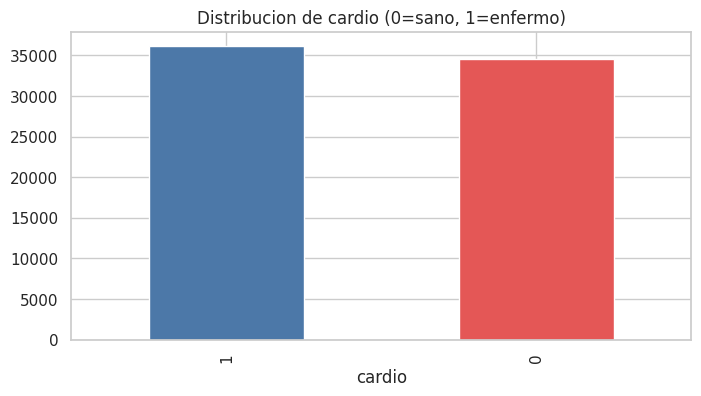

cardio
1    0.511
0    0.489
Name: proportion, dtype: float64


In [ ]:
ax = cardiodf['cardio'].value_counts().plot(kind='bar', color=['#4C78A8', '#E45756'])
ax.set_title('Distribucion de cardio (0=sano, 1=enfermo)'); ax.set_label(''); plt.show()
print(cardiodf['cardio'].value_counts(normalize=True).round(3))

El conjunto de datos se encuentra balanceado, ya que cuenta con el 51.1% de pacientes enfermos y 48.9% de pacientes sanos

**Deteccion visual de valores atipicos**

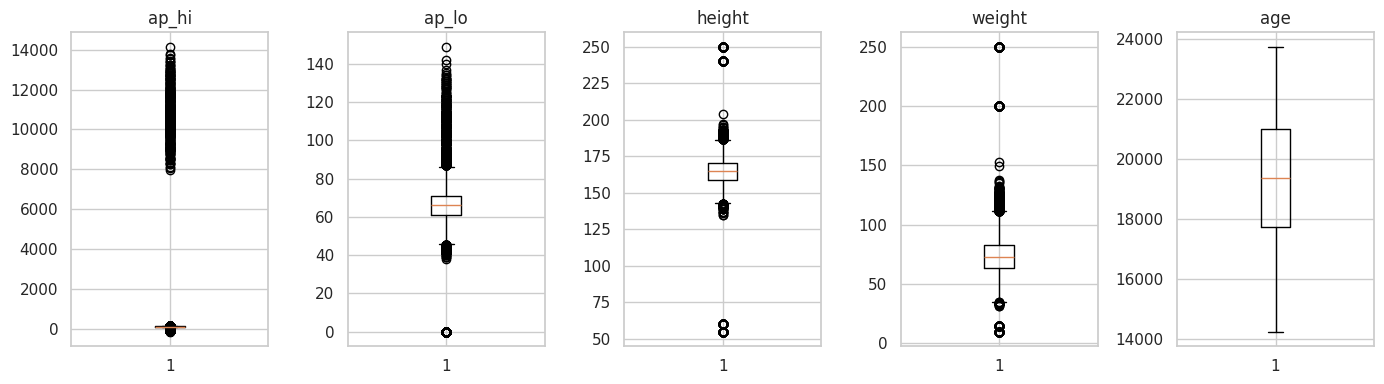

ap_hi min/max:  -140 14153
ap_lo min/max:  0.0 149.0
height min/max:  55 250
weight min/max:  10.0 250.0
age min/max:  14245 23741


In [ ]:
#.subplots(filas, columnas)
fig, axes = plt.subplots(1, 5, figsize=(14,4))
for ax, col in zip(axes, ['ap_hi', 'ap_lo', 'height', 'weight', 'age']):
  ax.boxplot(cardiodf[col].dropna())
  ax.set_title(col)
plt.tight_layout()
plt.show()

#valores maximos y minimos de cada variable
print('ap_hi min/max: ', cardiodf['ap_hi'].min(), cardiodf['ap_hi'].max())
print('ap_lo min/max: ', cardiodf['ap_lo'].min(), cardiodf['ap_lo'].max())
print('height min/max: ', cardiodf['height'].min(), cardiodf['height'].max())
print('weight min/max: ', cardiodf['weight'].min(), cardiodf['weight'].max())
print('age min/max: ', cardiodf['age'].min(), cardiodf['age'].max())

En el boxplot de la presion arterial sistolica (ap_hi), podemos observar observar un conjunto de valores aatipicos que nos indican resiones arteriales por arriba de 800 y por debajo de 0, por lo que lo hace humanamente imposible

Existen valores por encima de 130 en la presion arterial diastolica, lo cual puede indicar presencia de atipicos significativos. El mas preocupante es el valor atipico de 0. La distribucion de las presiones diastolicas se centra entre 60 y 70

Las distribuciones de las estaturas se centran entre 159 y 170 cm, tenemos valores por debajo de los 100 cm y por encima de los 200

La distribucion del peso esta entre 63 y 82 kg y tenemos valores por debajo de los 40 kg

**Porque no conviene analizar las distribuciones antes de la limpieza**
Un histograma sobre losd atos crudos queda inservivble: los valores imposibles aplastan toda la escala. Primero se limpia y luego se estudian los histogramas, sesgos y curtosis

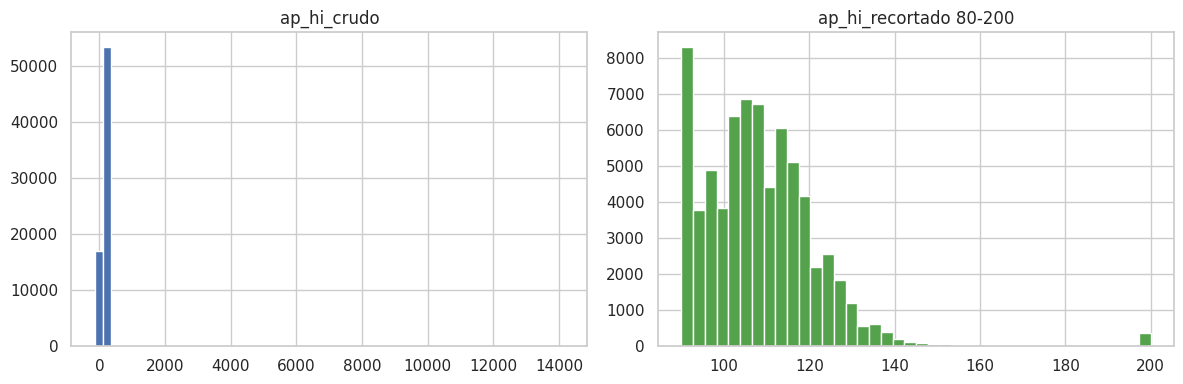

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
#histograma sin quotar atipicos
ax[0].hist(cardiodf['ap_hi'], bins = 60)
ax[0].set_title('ap_hi_crudo')

#histograma dejando valores en un rango de 90-200
ax[1].hist(cardiodf['ap_hi'].clip(90,200), bins=40, color='#54A24B')
ax[1].set_title('ap_hi_recortado 80-200')
plt.tight_layout()
plt.show()




# Limpieza de datos

Quitar duplicados

Convertir edad (dias --> años)

Filtrar imposibles

Imputar faltantes

Trabajar con variables derivadas (IMC, presion del pulso)

Quitar los atipicos estadisticos

Comparativa

In [ ]:
cardio_copy = cardiodf.copy()

antes = len(cardio_copy)
cardio_copy = cardio_copy.drop_duplicates()
print("Duplicados eliminados", antes - len(cardio_copy))

Duplicados eliminados 700


In [ ]:
print("Datos originales: ", len(cardiodf))
print("Datos actuales:" ), len(cardio_copy)

Datos originales:  70700
Datos actuales:


(None, 70000)

In [ ]:
#Convertir edad dias a años
cardio_copy['age_years'] = (cardio_copy['age']/365.25).round(1)
print(cardio_copy['age_years'])

0        50.9
1        45.1
2        55.3
3        53.9
4        62.8
         ... 
70695    54.8
70696    55.7
70697    46.4
70698    61.6
70699    54.0
Name: age_years, Length: 70000, dtype: float64


In [ ]:
#Filtrar datos humanamente imposibles
antes = len(cardio_copy)

cardio_copy = cardio_copy[cardio_copy['ap_hi'].between(60,250) & cardio_copy['ap_lo'].between(30,129)]
cardio_copy = cardio_copy[cardio_copy['ap_hi']> cardio_copy['ap_lo']]
cardio_copy = cardio_copy[cardio_copy['height'].between(130,210)]
cardio_copy = cardio_copy[cardio_copy['weight'].between(35,200)]

print("Filas eliminadas por valore atipicos imposibles: ", antes-len(cardio_copy))

Filas eliminadas por valore atipicos imposibles:  3821


In [ ]:
#Imputar valores faltantes
for faltante in ['weight', 'ap_lo']:
  #rellenamos valores faltantes de peso y presion sistolica con la mediana
  cardio_copy[faltante] = cardio_copy[faltante].fillna(cardio_copy[faltante].median())
for faltante in ['gluc', 'cholesterol']:
  #Rellenamos valoress faltantess de glucosa y colesterol con la moda porque son variables categoricas
  cardio_copy[faltante] = cardio_copy[faltante].fillna(cardio_copy[faltante].mode()[0].astype(int))

print('Faltantes restantes: ', int(cardio_copy.isna().sum().sum()))

Faltantes restantes:  0


In [ ]:
#Calcular la columna del imc con el peso y la estatura
#IMC = peso(kg)/ estatura en m
cardio_copy['imc'] = (cardio_copy['weight']/ (cardio_copy['height'] / 100)** 2).round(1)
cardio_copy['pulse_pressure'] = cardio_copy['ap_hi']- cardio_copy['ap_lo']
print(cardio_copy.info())

<class 'pandas.core.frame.DataFrame'>
Index: 66179 entries, 0 to 70699
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              66179 non-null  int64  
 1   age             66179 non-null  int64  
 2   gender          66179 non-null  int64  
 3   height          66179 non-null  int64  
 4   weight          66179 non-null  float64
 5   ap_hi           66179 non-null  int64  
 6   ap_lo           66179 non-null  float64
 7   cholesterol     66179 non-null  float64
 8   gluc            66179 non-null  float64
 9   smoke           66179 non-null  int64  
 10  alco            66179 non-null  int64  
 11  active          66179 non-null  int64  
 12  cardio          66179 non-null  int64  
 13  age_years       66179 non-null  float64
 14  imc             66179 non-null  float64
 15  pulse_pressure  66179 non-null  float64
dtypes: float64(7), int64(9)
memory usage: 8.6 MB
None


Una vez realizada la limpieza general del conjunto de datos, solo resta quitar variables que ya no son utiles (id, age)

In [ ]:
cardio_copy = cardio_copy.drop(columns=['id', 'age'])
print("Dataset limpio: ", cardio_copy.shape)
cardio_copy.head()

Dataset limpio:  (66179, 14)


,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,imc,pulse_pressure
0,2,176,81.9,96,58.0,1.0,2.0,0,0,1,0,50.9,26.4,38.0
1,1,166,65.1,114,65.0,1.0,1.0,0,0,1,0,45.1,23.6,49.0
2,1,157,76.4,119,77.0,1.0,1.0,1,0,1,0,55.3,31.0,42.0
3,1,167,78.9,136,60.0,1.0,1.0,0,0,1,1,53.9,28.3,76.0
4,2,176,80.6,98,80.0,1.0,1.0,1,0,1,0,62.8,26.0,18.0


Quitar outliers estadisticos (regla IQR) y su efecto

Ademas de los valores atipicos imposibles ya eliminados, pueden quedar outliers estadisticos: valores extremos pero posibles, como un paciente realmente hipertenso, los detectamos con la regla IQR(1.5x)

Q1 y Q3 son los percentiles de 25 y 75; IQR = Q3-Q1 es el rango del 50% central de los datos

Se marca como outlier todo lo que caiga fuera de [Q1-1.5 IQR, Q3+1.5 IQR] (los mismos "bigotes" del diagrama de caja)

In [ ]:
#seleccionamos las variables numericas del conjunto de datos
num_vars = ['age_years', 'height','weight', 'imc', 'ap_hi', 'ap_lo', 'pulse_pressure']
def limites_iqr(x):
  q1,q3 = x.quantile(0.25), x.quantile(0.75)
  iqr = q3 - q1
  return q1 - 1.5* iqr, q3+ 1.5*iqr


In [ ]:
#Seleccionamos los valores atipicos identificados
#Esta linea crea una serie booleana llena de falsos del mismo tamaño que el dataframe original que es la cardio_copu
#me va a servir para acumular todos los atipicos estadistcios de mi dataframe
mask_out = pd.Series(False, index=cardio_copy.index)
tabla_out = []
for atipico in num_vars:
  #se calcula el limite inferior y superor permitidos
  lo, hi = limites_iqr(cardio_copy[atipico])
  #se genera una mascara booleana para la col en turno, devuelve true si el valor es menor al limite inferior o mayor al limite superior
  mask = (cardio_copy[atipico] < lo) | (cardio_copy[atipico]>hi)
  #actualizamos la mascara general para que si una fila ya era considerada atipica en una columba anterior o en la actual se quede como true
  mask_out |= mask
  tabla_out.append([atipico, round(lo,1), round(hi,1), int(mask.sum()), f"{100*mask.mean():.2f}%"])

print(pd.DataFrame(tabla_out, columns = ['variable', 'limite inf', 'limite sup', 'n_outliers', '% atipicos']).to_string(index=False))
print(f"\n Filas con al menos un outliers: {int(mask_out.sum())} ({100*mask_out.mean():.2f})")


      variable  limite inf  limite sup  n_outliers % atipicos
     age_years        35.0        71.0           0      0.00%
        height       145.0       185.0         454      0.69%
        weight        35.2       111.2         598      0.90%
           imc        14.6        39.4         329      0.50%
         ap_hi        75.0       139.0         602      0.91%
         ap_lo        46.0        86.0         355      0.54%
pulse_pressure         9.0        73.0         211      0.32%

 Filas con al menos un outliers: 2066 (3.12)


In [ ]:
cardio_copy.describe().T

,count,mean,std,min,25%,50%,75%,max
gender,66179.0,1.346983,0.476014,1.0,1.0,1.0,2.0,2.0
height,66179.0,164.805482,7.644510,135.0,160.0,165.0,170.0,204.0
weight,66179.0,73.723164,15.047220,35.0,63.7,73.1,82.7,200.0
ap_hi,66179.0,107.385228,12.259563,60.0,99.0,107.0,115.0,162.0
ap_lo,66179.0,66.188020,7.347447,38.0,61.0,66.0,71.0,95.0
cholesterol,66179.0,1.182656,0.464752,1.0,1.0,1.0,1.0,3.0
gluc,66179.0,1.139969,0.411177,1.0,1.0,1.0,1.0,3.0
smoke,66179.0,0.077880,0.267984,0.0,0.0,0.0,0.0,1.0
alco,66179.0,0.051633,0.221286,0.0,0.0,0.0,0.0,1.0
active,66179.0,0.802082,0.398433,0.0,1.0,1.0,1.0,1.0


In [ ]:
#realizar una tbala comparativa antes/despues de outliers
antes_cardio = cardio_copy.copy() #antes de quitar los atipicos
cardio_copy = cardio_copy[~mask_out].reset_index(drop=True) #despue, esto es sin atipicos7


In [ ]:
def resumen(df_):
  return pd.DataFrame({
      'media': df_[num_vars].mean(),
      'std' : df_[num_vars].std(),
      'sesgo': df_[num_vars].apply(lambda s: skew(s)),
      'curtosis': df_[num_vars].apply(lambda s:kurtosis(s)),
  }).round(2)

In [ ]:
comparativa = pd.concat({'antes con los outliers': resumen(antes_cardio),
                         'despues sin los outliers': resumen(cardio_copy)}, axis=1)
print(f"Filas antes: {len(antes_cardio)} | despues {len(cardio_copy)} (se quito {100*(1-len(cardio_copy)/len(antes_cardio)):.1f}%)")
comparativa

Filas antes: 66179 | despues 64113 (se quito 3.1%)


antes con los outliers                        \
                                media    std sesgo curtosis   
age_years                       52.94   6.39 -0.07    -0.58   
height                         164.81   7.64  0.15    -0.03   
weight                          73.72  15.05  1.12     7.27   
imc                             27.09   4.95  1.56    15.23   
ap_hi                          107.39  12.26  0.14     0.12   
ap_lo                           66.19   7.35  0.06     0.02   
pulse_pressure                  41.20  11.53  0.05    -0.06   

               despues sin los outliers                        
                                  media    std sesgo curtosis  
age_years                         52.92   6.36 -0.07    -0.58  
height                           164.69   7.39  0.11    -0.29  
weight                            73.09  13.54  0.11    -0.29  
imc                               26.90   4.42 -0.04    -0.29  
ap_hi                            107.07  11.68  0.04    -0.25  
ap_lo                             66.08   7.10  0.02    -0.23  
pulse_pressure                    40.99  11.18 -0.03    -0.24

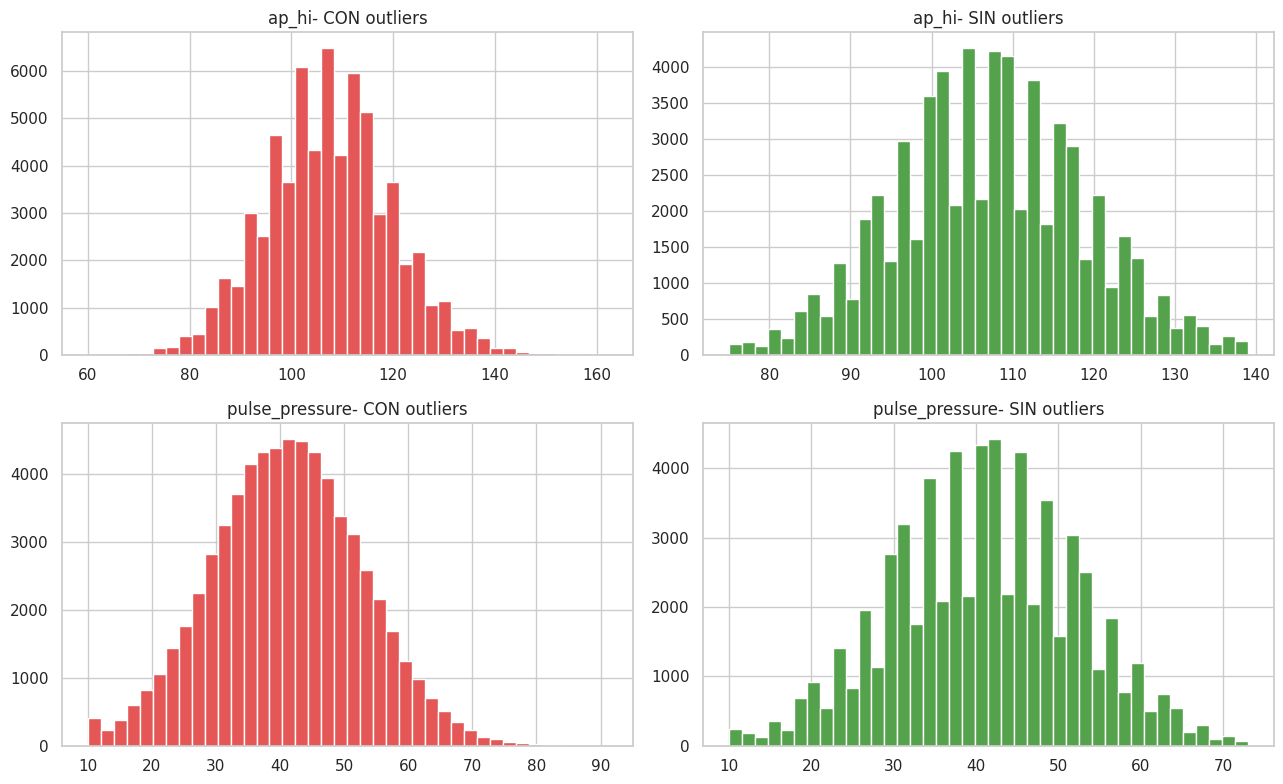

In [ ]:
fig, axes = plt.subplots(2,2, figsize=(13,8))
for row, col in zip (axes, ['ap_hi','pulse_pressure']):
  row[0].hist(antes_cardio[col], bins=40, color= '#E45756', edgecolor='white')
  row[0].set_title(f'{col}- CON outliers')
  row[1].hist(cardio_copy[col], bins=40, color= '#54A24B', edgecolor='white')
  row[1].set_title(f'{col}- SIN outliers')
plt.tight_layout()
plt.show()

El efecto de quitar los outliers se visualiza porque la std bajo y el sesgo y curtosis se acercan a una distribucion normal, en las medias no se muestra gran impacto. Aproximadamente se pierden entre el 3.1% de los registros

In [ ]:
#Guardar mi conjuntoo de datos limpio+
cardio_copy.to_csv('cardio_limpio.csv', sep = ';', index = False)
print("Guardado: cardio_limpio.csv", cardio_copy.shape)

Guardado: cardio_limpio.csv (64113, 14)


In [ ]:
cardio_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64113 entries, 0 to 64112
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          64113 non-null  int64  
 1   height          64113 non-null  int64  
 2   weight          64113 non-null  float64
 3   ap_hi           64113 non-null  int64  
 4   ap_lo           64113 non-null  float64
 5   cholesterol     64113 non-null  float64
 6   gluc            64113 non-null  float64
 7   smoke           64113 non-null  int64  
 8   alco            64113 non-null  int64  
 9   active          64113 non-null  int64  
 10  cardio          64113 non-null  int64  
 11  age_years       64113 non-null  float64
 12  imc             64113 non-null  float64
 13  pulse_pressure  64113 non-null  float64
dtypes: float64(7), int64(7)
memory usage: 6.8 MB


Histogramas - Post limpieza

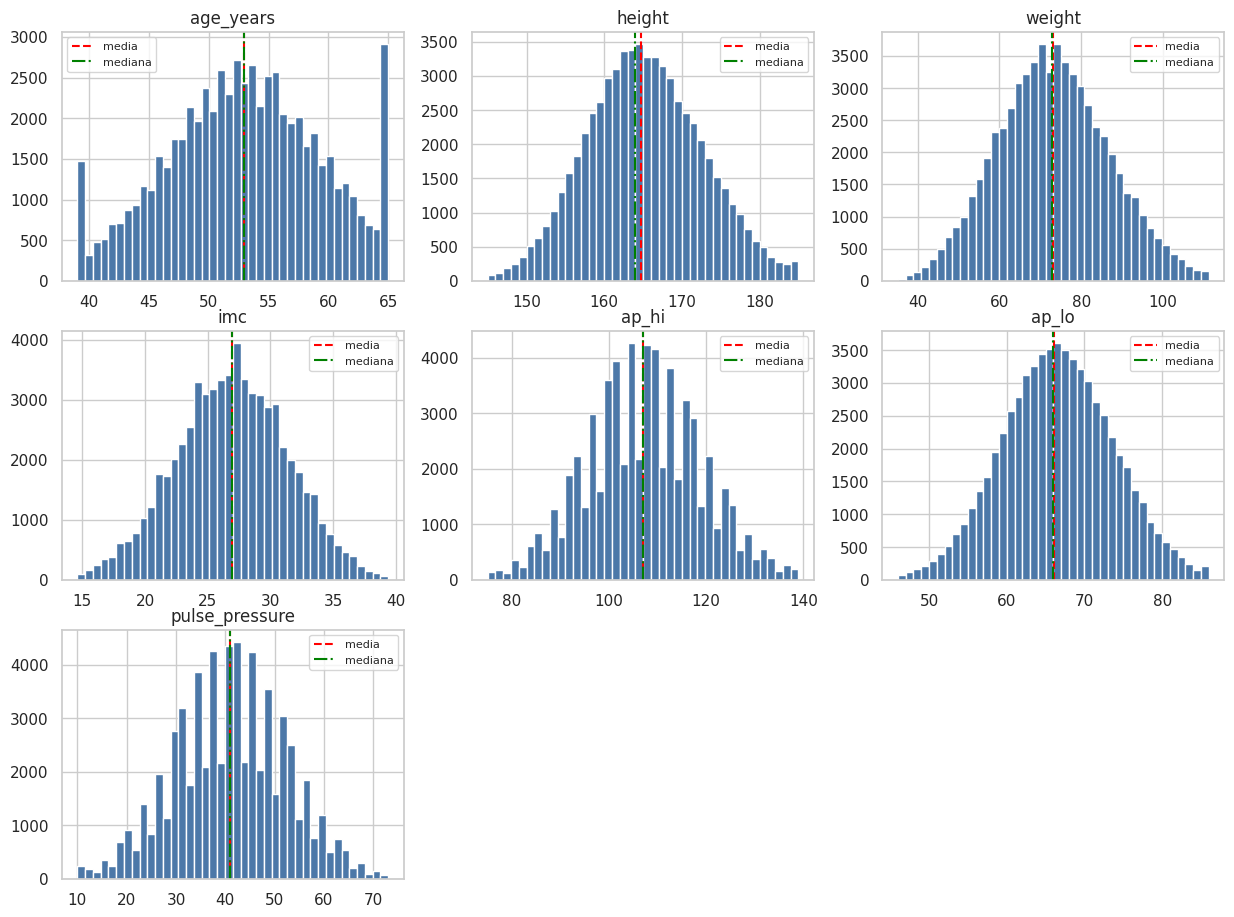

In [ ]:
num_var = ['age_years','height','bmi','ap_hi','ap_lo','pulse_pressure']
fig, axes = plt.subplots(3,3, figsize=(15,11))
for ax, col in zip (axes.ravel(), num_vars):
  ax.hist(cardio_copy[col],bins=40, color = '#4C78A8', edgecolor='white')
  ax.axvline(cardio_copy[col].mean(),color = 'red', ls='--', lw=1.5, label = 'media')
  ax.axvline(cardio_copy[col].median(),color='green', ls='-.', lw=1.5,label = 'mediana')
  ax.set_title(col)
  ax.legend(fontsize=8)
for ax in axes.ravel()[len(num_vars):]:
  ax.axis('off')
plt.tight_layout
plt.show()



*   Despues de realizar limpieza de datos, la media y mediana casi coinciden en todas la variables, lo cual me indicca que las distribuciones son aproximadamente simetricas (el sesgo practicamente no existe.)
*   Donde hay separacion de la media y la mediana, significa que hay asimetria leve, ver tabla de sesgo/curtosis
* age_years esta mas plana, lo cual significa que los pacientes se reparten de forma pareja entre aproximadamente 40 y 65 años



Sesgo (asimetria) y curtosis



*   sesgo(fisher): cuando es 0 es simetria, pero cuando era mayor que 0 tenia una cola en la derecha, menor que 0 significaba que tenia una cola en la izquierda
*   Curtosis: cuando es aproximadamente 0 quiere decir que es mesocurtica, cuando es mayor que 0 es leptocurtica, cuando es menor que 0 es lapticurtica



In [ ]:
def etiqueta_sesgo(s):
  a = abs(s)
  grado = 'aprox. simetrica' if a < 0.5 else('moderado 'if a < 1 else 'fuerte')
  if a < 0.5 : return grado
  return f"{grado} cola a la {'derecha (positivo)' if s > 0 else 'izquierda (negativo)'}"

def etiqueta_curt(k):
  if abs(k) < 0.5: return 'mesocurtica (=normal)'
  return 'leptocurtica (apuntada)' if k > 0 else 'platicurtica (aplanada)'

filas = []
for col in num_vars:
  s = skew(cardio_copy[col]); k = kurtosis(cardio_copy[col])
  filas.append([col, round(s,2), etiqueta_sesgo(s), round(k,2), etiqueta_curt(k)])


tabla = pd.DataFrame(filas, columns=['variable', 'sesgo', 'interpretacion sesgo', 'curtosis', 'interpretacion curtosis'])
tabla

,variable,sesgo,interpretacion sesgo,curtosis,interpretacion curtosis
0,age_years,-0.07,aprox. simetrica,-0.58,platicurtica (aplanada)
1,height,0.11,aprox. simetrica,-0.29,mesocurtica (=normal)
2,weight,0.11,aprox. simetrica,-0.29,mesocurtica (=normal)
3,imc,-0.04,aprox. simetrica,-0.29,mesocurtica (=normal)
4,ap_hi,0.04,aprox. simetrica,-0.25,mesocurtica (=normal)
5,ap_lo,0.02,aprox. simetrica,-0.23,mesocurtica (=normal)
6,pulse_pressure,-0.03,aprox. simetrica,-0.24,mesocurtica (=normal)




*   Despues de quitar los outliers, casi todas quedan aproximadamente simetricas (|sesgo| < 0.5) y cercanas a la normal, en age_years se ve que es ligeramente platicurtica (mas plana)




Diagramas de dispersion - relacion entre variables

Cada punto es un paciente (se muestran solo 5000 pacientes para que sea legible), el coeficiente r de Pearson resume la fuerza y el sentido de la relacion lineal    -1 <= r <= 1

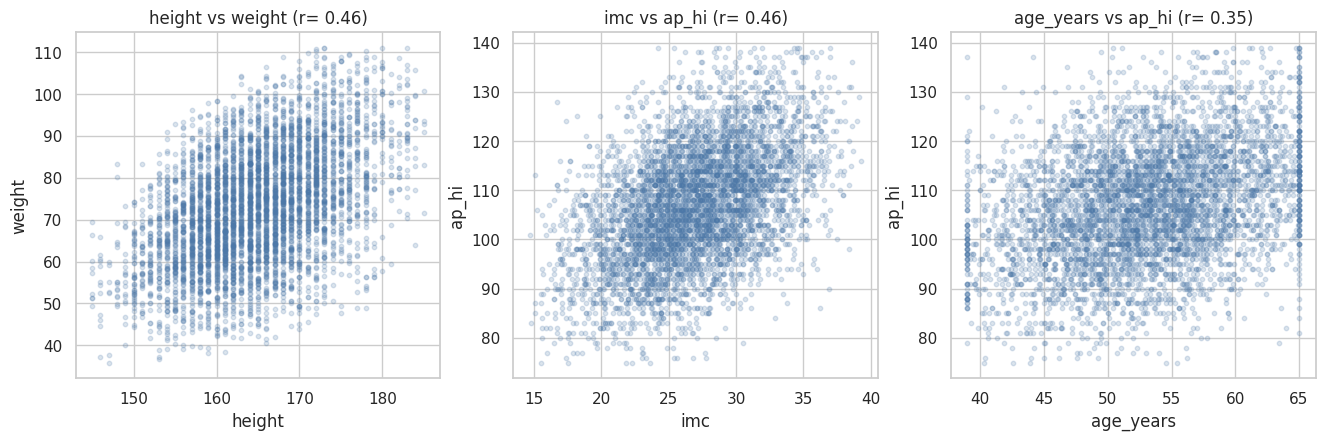

In [ ]:
muestra = cardio_copy.sample(5000, random_state = 0)
pares = [('height', 'weight'), ('imc', 'ap_hi'), ('age_years', 'ap_hi')]
fig, axes = plt.subplots(1,3, figsize= (16,4.5))
for ax, (x,y) in zip(axes, pares):
  ax.scatter(muestra[x], muestra[y], alpha = 0.2, s=10, c='#4C78A8')
  r, _ = pearsonr(cardio_copy[x], cardio_copy[y])
  ax.set_xlabel(x)
  ax.set_ylabel(y)
  ax.set_title(f'{x} vs {y} (r= {r:.2f})')
plt.tight_layout
plt.show()



*   La variable height y weight tienen relacion positiva (mas estatura = mas peso)
*   El IMC vs ap_hi tienen una relacion positiva, (a mas IMC, mayor presion ap_hi)
* Ninguna relacion es perfecta (nube dispersa): hay variabiliadad no explicada, por lo tanto los modelos no seran perfectos




Que variables separan a sanos de enfermos?

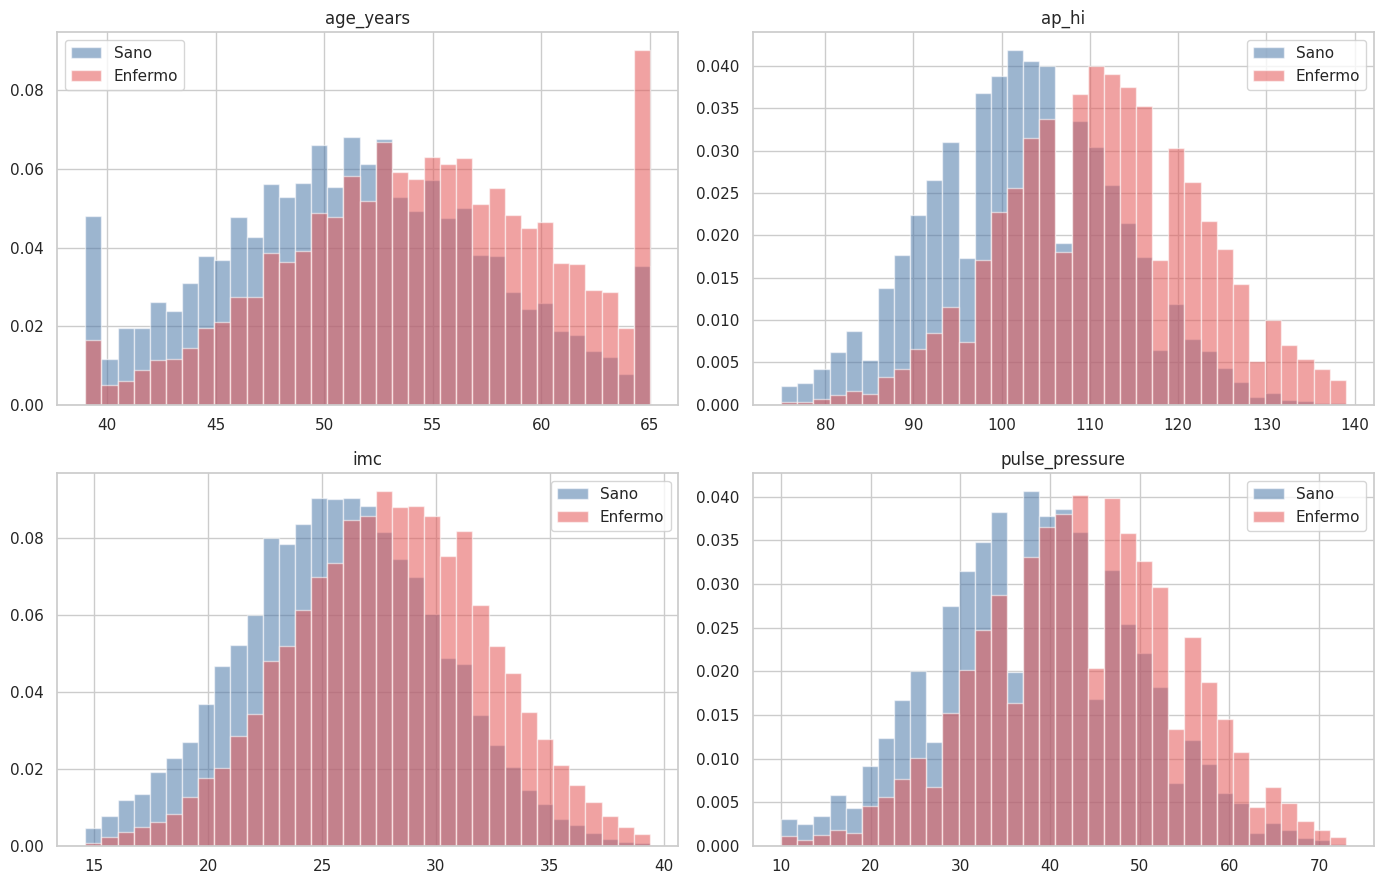

In [ ]:
comparar= ['age_years', 'ap_hi', 'imc', 'pulse_pressure']
fig, axes = plt.subplots(2,2, figsize = (14,9))
for ax, col in zip(axes.ravel(), comparar):
  for val, color in [(0,'#4C78A8'), (1, '#E45756')]:
    sub = cardio_copy[cardio_copy['cardio']== val][col]
    ax.hist(sub, bins=35, alpha=0.55, density= True, color=color, label=('Sano' if val ==0 else 'Enfermo'))
  ax.set_title(col)
  ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
#Diferencia de medias por clase para ver que variable separa mas
resumen = cardio_copy.groupby('cardio')[comparar + ['cholesterol', 'gluc']].mean().round(2).T
resumen.columns = ['Sano (0)', 'Enfermo (1)']
resumen['diferencia'] = (resumen['Enfermo (1)'] - resumen['Sano (0)']).round(2)
resumen


,Sano (0),Enfermo (1),diferencia
age_years,51.37,54.43,3.06
ap_hi,102.50,111.54,9.04
imc,25.79,27.99,2.20
pulse_pressure,38.40,43.51,5.11
cholesterol,1.06,1.28,0.22
gluc,1.10,1.17,0.07


Normalizacion

La normalizacion pone todas las variables en la misma escala apra los modelos que lo requoeran. No cambia la forma de la distribucion, solo la escala

In [ ]:
from sklearn.preprocessing import StandardScaler
num_vars = ['age_years', 'height', 'weight', 'imc', 'ap_hi', 'ap_lo', 'pulse_pressure']
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(cardio_copy[num_vars]), columns=num_vars)
print("Tras estandarizar (media =0, std = 1)")
print(Z.describe().loc[['mean', 'std', 'min', 'max']].round(2))

print("\n El sesgo no cambia con la estandarizacion")
print(pd.DataFrame({
    'sesgo orignal': cardio_copy[num_vars].apply(lambda s: round(skew(s),2)),
    'sesgo estandarizado': Z.apply(lambda s: round(skew(s),2))
}))

Tras estandarizar (media =0, std = 1)
      age_years  height  weight   imc  ap_hi  ap_lo  pulse_pressure
mean       0.00   -0.00    0.00 -0.00  -0.00   0.00           -0.00
std        1.00    1.00    1.00  1.00   1.00   1.00            1.00
min       -2.19   -2.67   -2.80 -2.79  -2.75  -2.83           -2.77
max        1.90    2.75    2.81  2.83   2.73   2.80            2.86

 El sesgo no cambia con la estandarizacion
                sesgo orignal  sesgo estandarizado
age_years               -0.07                -0.07
height                   0.11                 0.11
weight                   0.11                 0.11
imc                     -0.04                -0.04
ap_hi                    0.04                 0.04
ap_lo                    0.02                 0.02
pulse_pressure          -0.03                -0.03


#Regresion lineal --- predecir la presion sistolico
variable objetivo tiene que ser continua


In [ ]:
cardio_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64113 entries, 0 to 64112
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          64113 non-null  int64  
 1   height          64113 non-null  int64  
 2   weight          64113 non-null  float64
 3   ap_hi           64113 non-null  int64  
 4   ap_lo           64113 non-null  float64
 5   cholesterol     64113 non-null  float64
 6   gluc            64113 non-null  float64
 7   smoke           64113 non-null  int64  
 8   alco            64113 non-null  int64  
 9   active          64113 non-null  int64  
 10  cardio          64113 non-null  int64  
 11  age_years       64113 non-null  float64
 12  imc             64113 non-null  float64
 13  pulse_pressure  64113 non-null  float64
dtypes: float64(7), int64(7)
memory usage: 6.8 MB


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import statsmodels.api as sm

In [ ]:
feature = ['age_years']

X = cardio_copy[feature]
y = cardio_copy['ap_hi']
#viene el pase de entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print('Train: ', X_train.shape, '| Test: ', X_test.shape)

Train:  (51290, 1) | Test:  (12823, 1)


In [ ]:
#entrenar y probar
def evaluar_reg(resumen= True):
  #utilizando el scikit-learn
  reg_lin_scikit = LinearRegression().fit(X_train, y_train)
  pred_reg_lin_scikit = reg_lin_scikit.predict(X_test)

  #usando los stats
  reg_lin_stat = sm.OLS(y_train, sm.add_constant(X_train)).fit()
  pred_reg_lin_stat = reg_lin_stat.predict(sm.add_constant(X_test))

  #obtener las metricas de evalucaoco
  for nombre, pred in [('sklearn', pred_reg_lin_scikit), ('statsmodels', pred_reg_lin_stat)]:
    r2 = r2_score(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    mae = mean_absolute_error(y_test, pred)
    print(f'{nombre:12s} (test) R2 = {r2:.3f} RMSE={rmse:.2f} MAE={mae:.2f}')

    #resumen sobre train pero del stat
  if resumen:
    print(reg_lin_stat.summary())
  return reg_lin_scikit, pred_reg_lin_scikit, reg_lin_stat

In [ ]:
reg_lin_scikit, pred_reg_lin_scikit, reg_lin_stat = evaluar_reg()

sklearn      (test) R2 = 0.117 RMSE=10.95 MAE=8.74
statsmodels  (test) R2 = 0.117 RMSE=10.95 MAE=8.74
                            OLS Regression Results                            
Dep. Variable:                  ap_hi   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     7136.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:48:10   Log-Likelihood:            -1.9552e+05
No. Observations:               51290   AIC:                         3.910e+05
Df Residuals:                   51288   BIC:                         3.911e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

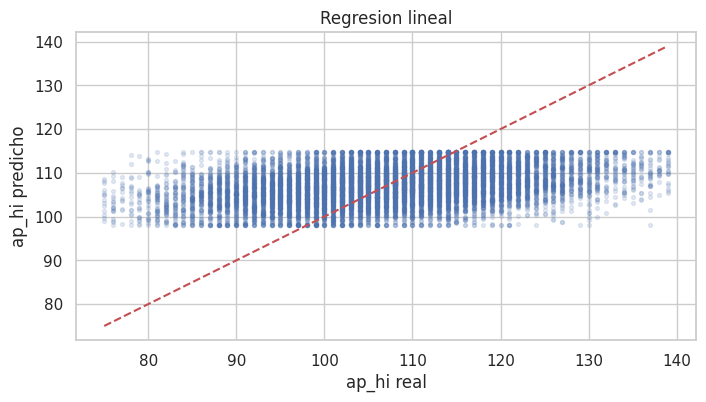

In [ ]:
plt.scatter(y_test, pred_reg_lin_scikit, alpha=0.15, s=8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('ap_hi real')
plt.ylabel('ap_hi predicho')
plt.title("Regresion lineal")
plt.show()

In [ ]:
feature = ['gender', 'height', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'imc']

X_mul = cardio_copy[feature]
y_mul = cardio_copy['ap_hi']
#viene el pase de entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X_mul, y_mul, test_size=0.2, random_state=0)
print('Train: ', X_train.shape, '| Test: ', X_test.shape)

Train:  (51290, 12) | Test:  (12823, 12)


In [ ]:
reg_lin_scikit, pred_reg_lin_scikit, reg_lin_stat = evaluar_reg()

sklearn      (test) R2 = 0.450 RMSE=8.64 MAE=6.91
statsmodels  (test) R2 = 0.450 RMSE=8.64 MAE=6.91
                            OLS Regression Results                            
Dep. Variable:                  ap_hi   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.449
Method:                 Least Squares   F-statistic:                     3481.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:48:28   Log-Likelihood:            -1.8357e+05
No. Observations:               51290   AIC:                         3.672e+05
Df Residuals:                   51277   BIC:                         3.673e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------------

Coeficientes de la regresion lineal(observar el efecto de cada variable sobre ap_hi)

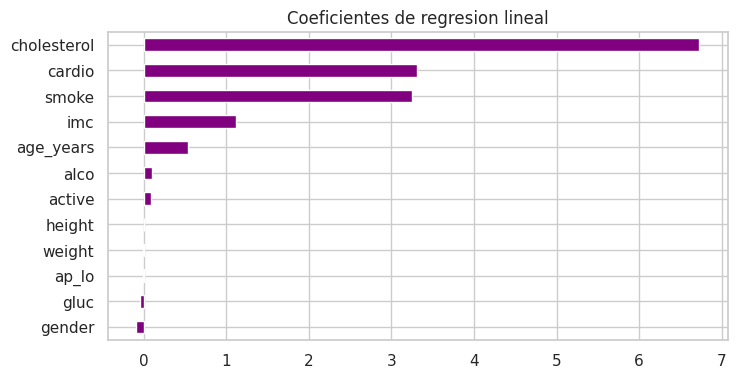

gender        -0.094
gluc          -0.042
ap_lo         -0.005
weight        -0.002
height         0.010
active         0.092
alco           0.108
age_years      0.544
imc            1.125
smoke          3.255
cardio         3.316
cholesterol    6.729
dtype: float64


In [ ]:
coef = pd.Series(reg_lin_scikit.coef_, index=feature).sort_values()
coef.plot(kind = 'barh', color = 'purple')
plt.title('Coeficientes de regresion lineal')
plt.show()
print(coef.round(3))

Valores reales vs predichos

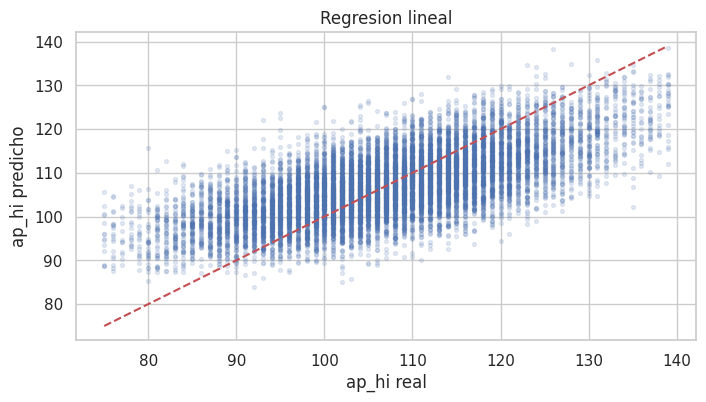

In [ ]:
plt.scatter(y_test, pred_reg_lin_scikit, alpha=0.15, s=8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('ap_hi real')
plt.ylabel('ap_hi predicho')
plt.title("Regresion lineal")
plt.show()

##Modelo 3

In [ ]:
feature = ['gender', 'height', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'imc']

X_modtre = cardio_copy[feature]
y_modtre = cardio_copy['ap_hi']
#viene el pase de entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X_modtre, y_modtre, test_size=0.2, random_state=0)
print('Train: ', X_train.shape, '| Test: ', X_test.shape)

Train:  (51290, 11) | Test:  (12823, 11)


In [ ]:
reg_lin_scikit, pred_reg_lin_scikit, reg_lin_stat = evaluar_reg()

sklearn      (test) R2 = 0.380 RMSE=9.18 MAE=7.36
statsmodels  (test) R2 = 0.380 RMSE=9.18 MAE=7.36
                            OLS Regression Results                            
Dep. Variable:                  ap_hi   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.375
Method:                 Least Squares   F-statistic:                     2797.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        05:17:45   Log-Likelihood:            -1.8680e+05
No. Observations:               51290   AIC:                         3.736e+05
Df Residuals:                   51278   BIC:                         3.737e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------------

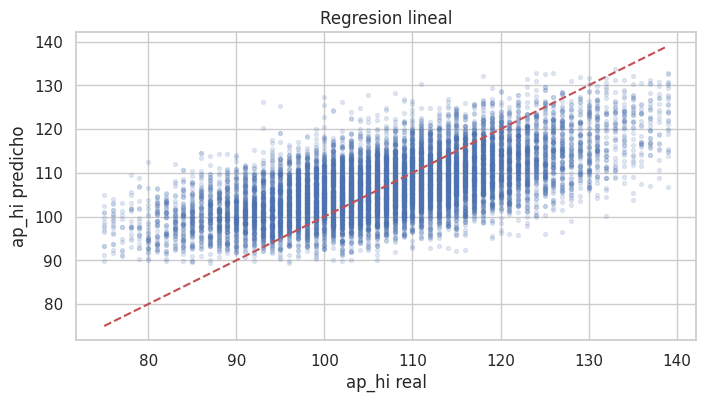

In [ ]:
plt.scatter(y_test, pred_reg_lin_scikit, alpha=0.15, s=8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('ap_hi real')
plt.ylabel('ap_hi predicho')
plt.title("Regresion lineal")
plt.show()

##Modelo 4

In [ ]:
feature = ['gender', 'ap_lo', 'gluc', 'weight']

X_modcua = cardio_copy[feature]
y_modcua = cardio_copy['ap_hi']
#viene el pase de entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X_modcua, y_modcua, test_size=0.2, random_state=0)
print('Train: ', X_train.shape, '| Test: ', X_test.shape)

Train:  (51290, 4) | Test:  (12823, 4)


In [ ]:
reg_lin_scikit, pred_reg_lin_scikit, reg_lin_stat = evaluar_reg()

sklearn      (test) R2 = 0.236 RMSE=10.19 MAE=8.18
statsmodels  (test) R2 = 0.236 RMSE=10.19 MAE=8.18
                            OLS Regression Results                            
Dep. Variable:                  ap_hi   R-squared:                       0.234
Model:                            OLS   Adj. R-squared:                  0.234
Method:                 Least Squares   F-statistic:                     3911.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:08:08   Log-Likelihood:            -1.9203e+05
No. Observations:               51290   AIC:                         3.841e+05
Df Residuals:                   51285   BIC:                         3.841e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

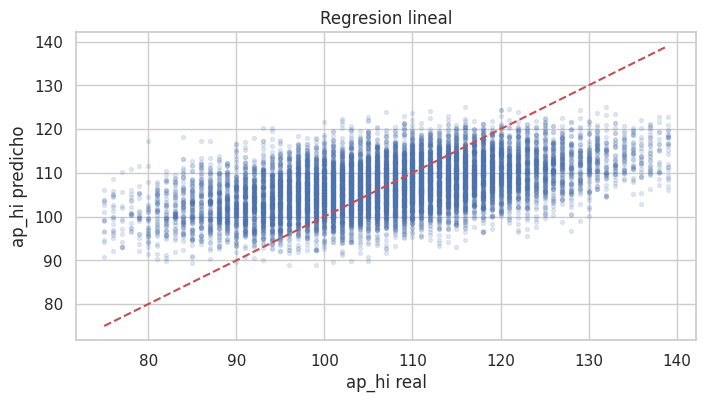

In [ ]:
plt.scatter(y_test, pred_reg_lin_scikit, alpha=0.15, s=8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('ap_hi real')
plt.ylabel('ap_hi predicho')
plt.title("Regresion lineal")
plt.show()

##Modelo 5

In [ ]:
feature = ['cholesterol', 'smoke', 'cardio', 'age_years', 'imc']

X_modcua = cardio_copy[feature]
y_modcua = cardio_copy['ap_hi']
#viene el pase de entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X_modcua, y_modcua, test_size=0.2, random_state=0)
print('Train: ', X_train.shape, '| Test: ', X_test.shape)

Train:  (51290, 5) | Test:  (12823, 5)


In [ ]:
reg_lin_scikit, pred_reg_lin_scikit, reg_lin_stat = evaluar_reg()

sklearn      (test) R2 = 0.450 RMSE=8.64 MAE=6.91
statsmodels  (test) R2 = 0.450 RMSE=8.64 MAE=6.91
                            OLS Regression Results                            
Dep. Variable:                  ap_hi   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.449
Method:                 Least Squares   F-statistic:                     8355.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:30:03   Log-Likelihood:            -1.8358e+05
No. Observations:               51290   AIC:                         3.672e+05
Df Residuals:                   51284   BIC:                         3.672e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------------

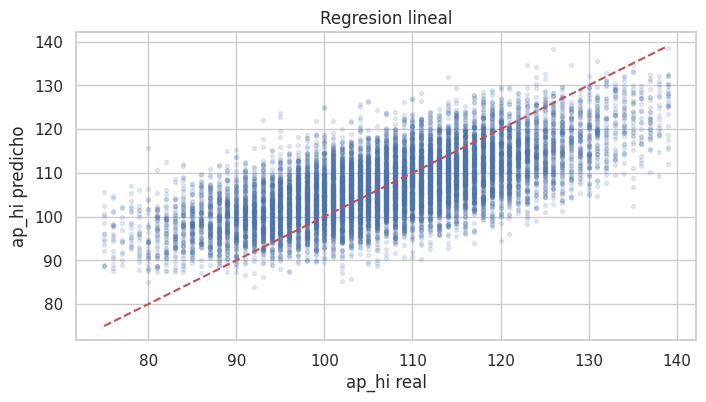

In [ ]:
plt.scatter(y_test, pred_reg_lin_scikit, alpha=0.15, s=8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('ap_hi real')
plt.ylabel('ap_hi predicho')
plt.title("Regresion lineal")
plt.show()